In [1]:
from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event
from collections import defaultdict
import pandas as pd

event_file = "../tb_logs/res_validator/idle__20260113_104214__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768318934.elahe-LEGION-T7-34IAS10.492429.0"

scalars = defaultdict(list)

for raw in tf_record.tf_record_iterator(event_file):
    event = Event.FromString(raw)

    if not event.summary:
        continue

    for v in event.summary.value:
        if v.HasField("simple_value"):
            scalars[v.tag].append({
                "step": event.step,
                "value": v.simple_value,
                "wall_time": event.wall_time,
            })

print("Scalar tags found:")
for tag in scalars:
    print(tag)


2026-01-14 09:47:05.672043: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-14 09:47:05.702236: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-14 09:47:06.388347: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`
Scalar tags found:
reward/total
action/index
action/sum
throughput/embb_mbps
throughput/urllc_mbps
latency/urllc
queues/embb_bytes
queues/urllc_bytes
prb/reserve_fraction
prb/effective_ratio
obs/embb_demand_prb
obs/urllc_demand_prb
obs/embb_throughput
obs/urllc_throughput
obs/embb_queue
obs/urllc_queue
obs/embb_base_achievable_throughput
obs/urllc_base_achievable_throughput
obs/reserve_used_prb
obs/effective_max_prb
state/embb_demand_norm
state/urllc_demand_norm
state/embb_queue_norm
state/urllc_queue_norm
state/embb_thr_norm
state/urllc_thr_norm
state/urllc_lat_excess_norm
state/effective_prb_ratio
state/reserve_used_norm
state/prev_action_e_norm
state/prev_action_u_norm
state/state_11
state/state_12
satisfaction/eMBB_capped
satisfaction/eMBB_raw
satisfaction/URLLC_capped
satisfaction/URLLC_raw
episode/return
episode/length


In [2]:
rows = []
for tag, values in scalars.items():
    for v in values:
        rows.append({
            "tag": tag,
            "step": int(v["step"]),
            "value": v["value"],
        })

df = pd.DataFrame(rows)
df = df.sort_values("step").reset_index(drop=True)

df.head()


,tag,step,value
0,episode/length,0,9.990000e+02
1,episode/return,0,0.000000e+00
2,episode/return,1,4.026712e+09
3,episode/length,1,9.990000e+02
4,episode/length,2,9.990000e+02


In [3]:
wide = df.pivot_table(
    index="step",
    columns="tag",
    values="value",
    aggfunc="last"
).reset_index()

wide.head()


tag,step,action/index,action/sum,episode/length,episode/return,latency/urllc,obs/effective_max_prb,obs/embb_base_achievable_throughput,obs/embb_demand_prb,obs/embb_queue,...,state/prev_action_u_norm,state/reserve_used_norm,state/state_11,state/state_12,state/urllc_demand_norm,state/urllc_lat_excess_norm,state/urllc_queue_norm,state/urllc_thr_norm,throughput/embb_mbps,throughput/urllc_mbps
0,0,NaN,NaN,999.0,0.000000e+00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,NaN,999.0,4.026712e+09,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,999.0,-5.783739e+02,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,999.0,0.000000e+00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,NaN,NaN,999.0,-1.500655e+02,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
wide["jamming"] = wide["prb/effective_ratio"] < 0.999
wide["jammed_fraction"] = 1.0 - wide["prb/effective_ratio"]
wide["jamming"].value_counts()

jamming
False    37409
True     12587
Name: count, dtype: int64

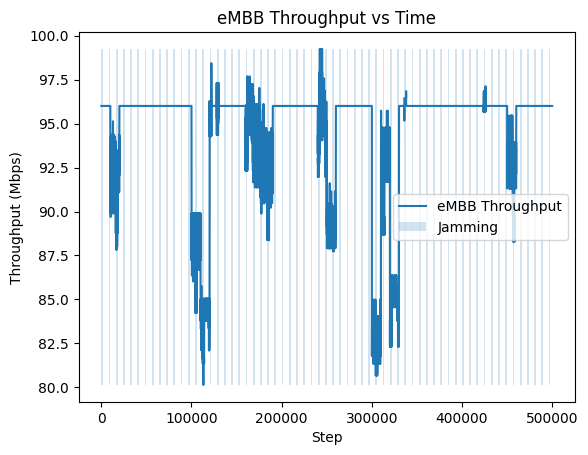

In [6]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(wide["step"], wide["throughput/embb_mbps"], label="eMBB Throughput")

# shade jamming periods
plt.fill_between(
    wide["step"],
    wide["throughput/embb_mbps"].min(),
    wide["throughput/embb_mbps"].max(),
    where=wide["jamming"],
    alpha=0.2,
    label="Jamming"
)

plt.xlabel("Step")
plt.ylabel("Throughput (Mbps)")
plt.legend()
plt.title("eMBB Throughput vs Time")
plt.show()


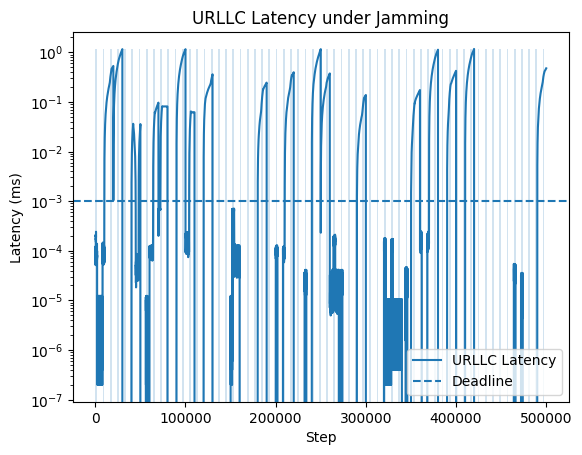

In [9]:
URLLC_DEADLINE = 0.001  # ms (set your real value)

plt.figure()
plt.plot(wide["step"], wide["latency/urllc"], label="URLLC Latency")
plt.axhline(URLLC_DEADLINE, linestyle="--", label="Deadline")

plt.fill_between(
    wide["step"],
    wide["latency/urllc"].min(),
    wide["latency/urllc"].max(),
    where=wide["jamming"],
    alpha=0.2
)

plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("Latency (ms)")
plt.legend()
plt.title("URLLC Latency under Jamming")
plt.show()
